# 07 - Avaliação (métricas da Aula 08) e generalização

Todas as métricas deste notebook são calculadas com os modelos **carregados dos arquivos `.pt`** (notebook 06),
não com objetos em memória do treinamento. A configuração final e o limiar já estavam congelados no notebook 05
antes de o teste ser consultado.

1. Métricas de regressão e classificação (baseline × final, treino/validação/teste) e comparação opcional com a
   Atividade 2;
2. matriz de confusão, curvas ROC e PR, efeito do limiar;
3. análise de resíduos;
4. generalização: gap, curvas de aprendizado, validação cruzada K-fold, diagnóstico de over/underfitting e
   trade-off viés × variância.

In [1]:
import json
import sys
from pathlib import Path

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import precision_recall_curve, roc_curve
from sklearn.model_selection import StratifiedKFold, train_test_split

from src import inference
from src.config import MODELS, SEMENTES, TABLES, indices_split, ler_dataset, preparar, salvar_fig, salvar_tabela
from src.experiments import carregar_log, chave_cfg, estudos, montar_cfg, resumir
from src.metrics import (diagnostico, gap, gap_relativo, matriz_confusao, metricas_classificacao,
                         metricas_regressao)
from src.train import avaliar, executar

torch.set_num_threads(1)
AT2 = RAIZ.parent / "atividade_02" / "reports" / "tables"

## 1. Predições dos modelos carregados

In [2]:
def conjuntos(problema):
    df = ler_dataset(problema)
    idx_tr, idx_val, idx_te, _ = indices_split(df)
    return {"treino": df.loc[idx_tr], "validação": df.loc[idx_val], "teste": df.loc[idx_te]}

CONJ = {p: conjuntos(p) for p in ("regressao", "classificacao")}
MODELOS = {p: {nome: inference.carregar(MODELS / f"{arq}_{p}.pt")
               for nome, arq in (("Baseline", "baseline"), ("Final", "modelo"))}
           for p in ("regressao", "classificacao")}
for p in MODELOS:
    for nome, (m, ck) in MODELOS[p].items():
        print(p, nome, ck["config"]["hidden"], ck["config"]["activation"], "| otimizador:",
              ck["hiperparametros"]["otimizador"], "| lr:", ck["hiperparametros"]["lr"],
              "| batch:", ck["hiperparametros"]["batch"], "| limiar:", ck.get("limiar", "-"))

regressao Baseline [32, 32] ReLU | otimizador: Adam | lr: 0.001 | batch: 32 | limiar: -
regressao Final [32, 32] Sigmoid | otimizador: AdamW | lr: 0.00016 | batch: 16 | limiar: -
classificacao Baseline [32, 32] ReLU | otimizador: Adam | lr: 0.001 | batch: 32 | limiar: 0.5
classificacao Final [8] Tanh | otimizador: RMSprop | lr: 0.00162 | batch: 16 | limiar: 0.5


## 2. Regressão: MAE, MSE, RMSE, MAPE, R², MedAE

In [3]:
linhas = []
PREV_REG = {}
for nome, (m, ck) in MODELOS["regressao"].items():
    for conj, df in CONJ["regressao"].items():
        prev = inference.prever(m, ck, df).iloc[:, 0].to_numpy()
        PREV_REG[(nome, conj)] = prev
        linhas.append({"modelo": f"MLP {nome}", "conjunto": conj, **metricas_regressao(df[ck["target"]].astype(float), prev)})
met_reg = pd.DataFrame(linhas)
salvar_tabela(met_reg, "metricas_regressao")
met_reg.round(3)

,modelo,conjunto,MAE,MSE,RMSE,MAPE (%),R2,MedAE
0,MLP Baseline,treino,9.217,133.758,11.565,5.740,0.706,7.907
1,MLP Baseline,validação,9.325,137.431,11.723,5.790,0.689,7.849
2,MLP Baseline,teste,9.787,151.990,12.328,6.138,0.669,8.303
3,MLP Final,treino,9.386,138.515,11.769,5.838,0.695,8.037
4,MLP Final,validação,9.369,136.252,11.673,5.804,0.691,8.057
5,MLP Final,teste,9.665,147.965,12.164,6.060,0.678,8.130


**Variação entre sementes no teste (configuração final):** o notebook 05 avaliou no teste as 5 sementes da
configuração final (depois de congelada). O modelo salvo é a semente de melhor validação.

In [4]:
sem_reg = pd.read_csv(TABLES / "final_sementes_teste_regressao.csv")
display(sem_reg.round(3))
print("Média ± desvio no teste:", {c: f"{sem_reg[c].mean():.3f} ± {sem_reg[c].std():.3f}" for c in ["RMSE", "MAE", "R2"]})

,seed,salvo,limiar,melhor_epoca,val_RMSE,MAE,MSE,RMSE,MAPE (%),R2,MedAE
0,0,False,0.5,94,11.687,9.650,147.757,12.156,6.052,0.678,8.085
1,1,False,0.5,89,11.685,9.652,147.803,12.157,6.055,0.678,8.056
2,2,False,0.5,107,11.680,9.647,147.960,12.164,6.049,0.678,8.097
3,3,True,0.5,121,11.673,9.665,147.965,12.164,6.060,0.678,8.130
4,4,False,0.5,107,11.682,9.665,148.263,12.176,6.066,0.677,8.142


Média ± desvio no teste: {'RMSE': '12.163 ± 0.008', 'MAE': '9.656 ± 0.009', 'R2': '0.678 ± 0.000'}


**Comparação opcional com a Atividade 2** (mesmo conjunto de teste de 1.800 pacientes). A árvore e os ensembles
foram treinados nos 7.200 pacientes de treino; a rede usa 5.760 para ajustar os pesos e 1.440 para validação
(early stopping). Referência trivial: prever a média do treino daria RMSE ≈ 21,4 bpm e R² ≈ 0.

In [5]:
at2 = pd.read_csv(AT2 / "metricas_regressao.csv")
at2 = at2[at2["modelo"].isin(["Árvore (ajustada)", "Random Forest", "Gradient Boosting"]) & (at2["conjunto"] == "teste")]
comp_reg = pd.concat([at2, met_reg[met_reg["conjunto"] == "teste"]], ignore_index=True)
salvar_tabela(comp_reg, "comparacao_atividade2_regressao")
comp_reg.round(3)

,modelo,conjunto,MAE,MSE,RMSE,MAPE (%),R2,MedAE
0,Árvore (ajustada),teste,9.778,151.227,12.297,6.134,0.671,8.148
1,Random Forest,teste,9.667,147.095,12.128,6.065,0.680,8.184
2,Gradient Boosting,teste,9.588,145.775,12.074,6.010,0.683,8.043
3,MLP Baseline,teste,9.787,151.990,12.328,6.138,0.669,8.303
4,MLP Final,teste,9.665,147.965,12.164,6.060,0.678,8.130


## 3. Classificação: matriz de confusão, Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC

O problema é binário, então não há média macro/weighted: as métricas são da classe positiva (com doença).

In [6]:
linhas = []
PROB = {}
for nome, (m, ck) in MODELOS["classificacao"].items():
    for conj, df in CONJ["classificacao"].items():
        prev = inference.prever(m, ck, df)
        prob = prev.iloc[:, 0].to_numpy()
        PROB[(nome, conj)] = prob
        y = df[ck["target"]].to_numpy()
        linhas.append({"modelo": f"MLP {nome}", "conjunto": conj, "limiar": ck["limiar"],
                       **metricas_classificacao(y, (prob >= ck["limiar"]).astype(int), prob)})
met_clf = pd.DataFrame(linhas)
salvar_tabela(met_clf, "metricas_classificacao")
met_clf.round(4)

,modelo,conjunto,limiar,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,MLP Baseline,treino,0.5,0.9104,0.8601,0.8414,0.8506,0.9643,0.9311
1,MLP Baseline,validação,0.5,0.9000,0.8650,0.7936,0.8278,0.9484,0.9098
2,MLP Baseline,teste,0.5,0.8861,0.8232,0.7945,0.8086,0.9445,0.9007
3,MLP Final,treino,0.5,0.9033,0.8380,0.8442,0.8411,0.9574,0.9184
4,MLP Final,validação,0.5,0.9007,0.8547,0.8096,0.8316,0.9492,0.9113
5,MLP Final,teste,0.5,0.8933,0.8324,0.8110,0.8216,0.9503,0.9093


In [7]:
sem_clf = pd.read_csv(TABLES / "final_sementes_teste_classificacao.csv")
display(sem_clf.round(4))
print("Média ± desvio no teste:", {c: f"{sem_clf[c].mean():.4f} ± {sem_clf[c].std():.4f}" for c in ["F1", "Recall", "Precision", "PR-AUC", "ROC-AUC"]})

,seed,salvo,limiar,melhor_epoca,val_F1,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,0,False,0.50,14,0.8288,0.8889,0.8236,0.8055,0.8145,0.9490,0.9070
1,1,False,0.53,12,0.8270,0.8939,0.8444,0.7963,0.8196,0.9488,0.9063
2,2,False,0.51,5,0.8219,0.8967,0.8432,0.8092,0.8258,0.9502,0.9093
3,3,False,0.52,8,0.8242,0.8922,0.8293,0.8110,0.8200,0.9496,0.9066
4,4,True,0.50,3,0.8316,0.8933,0.8324,0.8110,0.8216,0.9503,0.9093


Média ± desvio no teste: {'F1': '0.8203 ± 0.0041', 'Recall': '0.8066 ± 0.0062', 'Precision': '0.8346 ± 0.0090', 'PR-AUC': '0.9077 ± 0.0015', 'ROC-AUC': '0.9496 ± 0.0007'}


In [8]:
at2c = pd.read_csv(AT2 / "metricas_classificacao.csv")
at2c = at2c[at2c["modelo"].isin(["Árvore (ajustada)", "Random Forest", "Gradient Boosting"]) & (at2c["conjunto"] == "teste")]
comp_clf = pd.concat([at2c, met_clf[met_clf["conjunto"] == "teste"].drop(columns="limiar")], ignore_index=True)
salvar_tabela(comp_clf, "comparacao_atividade2_classificacao")
comp_clf.round(4)

,modelo,conjunto,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Árvore (ajustada),teste,0.8567,0.7808,0.7321,0.7557,0.8848,0.7931
1,Random Forest,teste,0.8756,0.8000,0.7853,0.7926,0.9394,0.8843
2,Gradient Boosting,teste,0.8894,0.8545,0.7651,0.8074,0.9451,0.9006
3,MLP Baseline,teste,0.8861,0.8232,0.7945,0.8086,0.9445,0.9007
4,MLP Final,teste,0.8933,0.8324,0.8110,0.8216,0.9503,0.9093


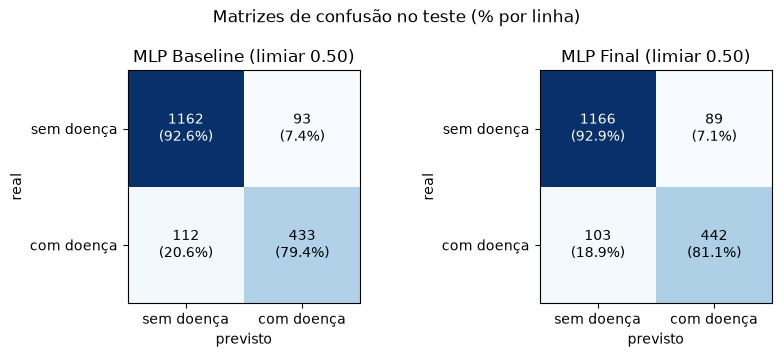

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(8.5, 3.6))
y_te = CONJ["classificacao"]["teste"]["has_heart_disease"].to_numpy()
for ax, nome in zip(axes, ("Baseline", "Final")):
    lim = MODELOS["classificacao"][nome][1]["limiar"]
    cm = matriz_confusao(y_te, (PROB[(nome, "teste")] >= lim).astype(int))
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]}\n({100 * cm[i, j] / cm[i].sum():.1f}%)", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=10)
    ax.set_xticks([0, 1], ["sem doença", "com doença"]); ax.set_yticks([0, 1], ["sem doença", "com doença"])
    ax.set(xlabel="previsto", ylabel="real", title=f"MLP {nome} (limiar {lim:.2f})")
fig.suptitle("Matrizes de confusão no teste (% por linha)"); fig.tight_layout()
salvar_fig("matrizes_confusao")
plt.show()

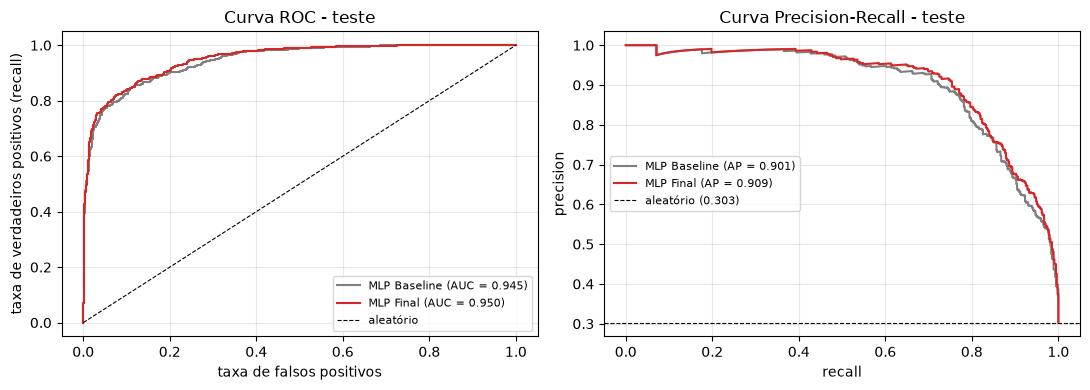

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for nome, cor in (("Baseline", "#7f7f7f"), ("Final", "#d62728")):
    prob = PROB[(nome, "teste")]
    fpr, tpr, _ = roc_curve(y_te, prob)
    auc = met_clf[(met_clf['modelo'] == 'MLP ' + nome) & (met_clf['conjunto'] == 'teste')]["ROC-AUC"].item()
    axes[0].plot(fpr, tpr, color=cor, label=f"MLP {nome} (AUC = {auc:.3f})")
    p, r, _ = precision_recall_curve(y_te, prob)
    ap = met_clf[(met_clf['modelo'] == 'MLP ' + nome) & (met_clf['conjunto'] == 'teste')]["PR-AUC"].item()
    axes[1].plot(r, p, color=cor, label=f"MLP {nome} (AP = {ap:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=0.8, label="aleatório")
axes[0].set(xlabel="taxa de falsos positivos", ylabel="taxa de verdadeiros positivos (recall)", title="Curva ROC - teste")
axes[1].axhline(y_te.mean(), color="k", ls="--", lw=0.8, label=f"aleatório ({y_te.mean():.3f})")
axes[1].set(xlabel="recall", ylabel="precision", title="Curva Precision-Recall - teste")
for ax in axes:
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout()
salvar_fig("curvas_roc_pr")
plt.show()

### Limiar de decisão

O limiar do modelo final foi escolhido **na validação** (notebook 05), maximizando o F1. Como num rastreamento
de doença cardíaca o falso negativo (doente liberado) custa mais que o falso positivo (exame adicional),
avalia-se também um **limiar de alta sensibilidade**, também escolhido só na validação: o maior limiar com
recall ≥ 0,90. O gráfico mostra o compromisso precision × recall na validação; a tabela mostra o efeito dos dois
limiares no teste (apenas para relatar o efeito, o teste não muda nenhuma escolha).

Limiar F1-ótimo (validação): 0.50 | maior limiar com recall >= 0,90 (validação): 0.23


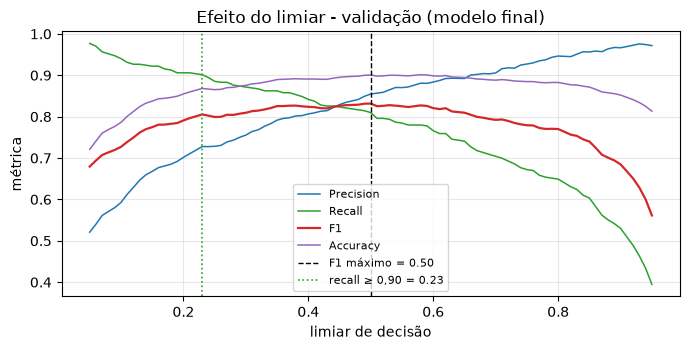

,critério,limiar,conjunto,Accuracy,Precision,Recall,F1,FN,FP
0,F1 máximo,0.50,validação,0.9007,0.8547,0.8096,0.8316,83,60
1,F1 máximo,0.50,teste,0.8933,0.8324,0.8110,0.8216,103,89
2,"recall ≥ 0,90",0.23,validação,0.8681,0.7278,0.9014,0.8053,43,147
3,"recall ≥ 0,90",0.23,teste,0.8561,0.7115,0.8826,0.7879,64,195


In [11]:
m_fin, ck_fin = MODELOS["classificacao"]["Final"]
y_val = CONJ["classificacao"]["validação"]["has_heart_disease"].to_numpy()
prob_val = PROB[("Final", "validação")]
limiares = np.round(np.arange(0.05, 0.96, 0.01), 2)
curva = pd.DataFrame([{"limiar": t, **metricas_classificacao(y_val, (prob_val >= t).astype(int))} for t in limiares])
lim_rec90 = float(curva.loc[curva["Recall"] >= 0.90, "limiar"].max())
print(f"Limiar F1-ótimo (validação): {ck_fin['limiar']:.2f} | maior limiar com recall >= 0,90 (validação): {lim_rec90:.2f}")
fig, ax = plt.subplots(figsize=(7, 3.6))
for c, cor in (("Precision", "#1f77b4"), ("Recall", "#2ca02c"), ("F1", "#d62728"), ("Accuracy", "#9467bd")):
    ax.plot(curva["limiar"], curva[c], label=c, color=cor, lw=1.6 if c == "F1" else 1.1)
ax.axvline(ck_fin["limiar"], color="k", ls="--", lw=1, label=f"F1 máximo = {ck_fin['limiar']:.2f}")
ax.axvline(lim_rec90, color="#2ca02c", ls=":", lw=1.2, label=f"recall ≥ 0,90 = {lim_rec90:.2f}")
ax.set(xlabel="limiar de decisão", ylabel="métrica", title="Efeito do limiar - validação (modelo final)")
ax.legend(fontsize=8); ax.grid(alpha=0.3); fig.tight_layout()
salvar_fig("limiar_validacao")
plt.show()

prob_te = PROB[("Final", "teste")]
linhas = []
for nome_lim, t in (("F1 máximo", ck_fin["limiar"]), ("recall ≥ 0,90", lim_rec90)):
    for conj, y, p in (("validação", y_val, prob_val), ("teste", y_te, prob_te)):
        cm = matriz_confusao(y, (p >= t).astype(int))
        linhas.append({"critério": nome_lim, "limiar": t, "conjunto": conj,
                       **metricas_classificacao(y, (p >= t).astype(int), p),
                       "FN": int(cm[1, 0]), "FP": int(cm[0, 1])})
efeito = pd.DataFrame(linhas)
salvar_tabela(efeito, "efeito_limiar")
efeito.drop(columns=["ROC-AUC", "PR-AUC"]).round(4)

## 4. Resíduos (regressão, escala original em bpm)

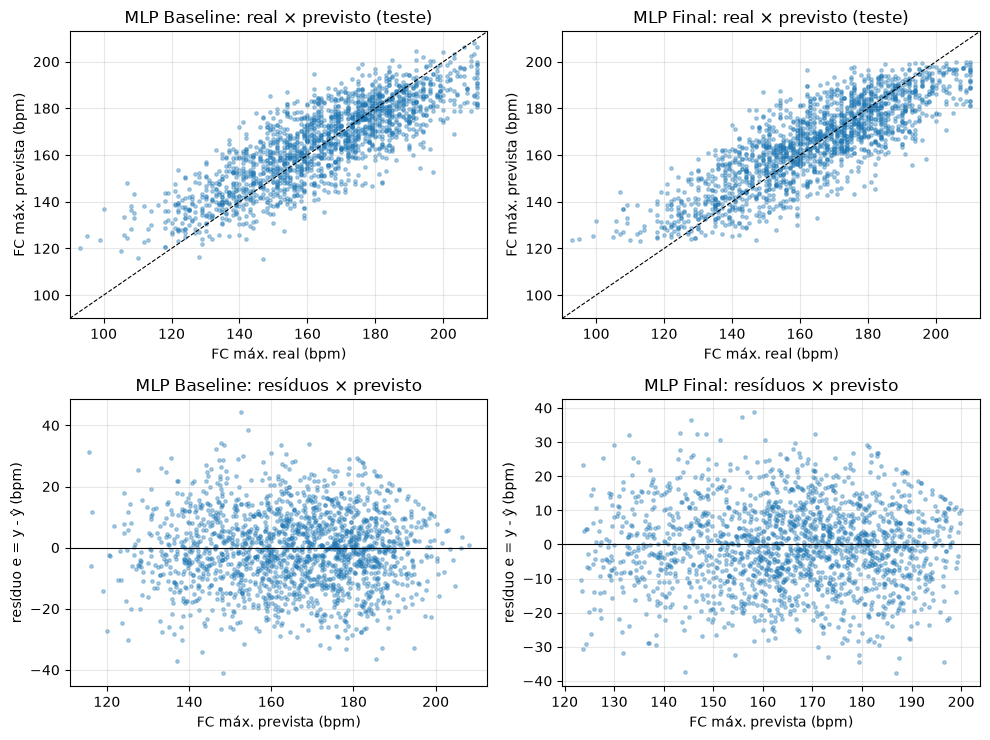

In [12]:
df_te = CONJ["regressao"]["teste"]
y = df_te["max_heart_rate_achieved"].to_numpy()
fig, axes = plt.subplots(2, 2, figsize=(10, 7.5))
for col, nome in enumerate(("Baseline", "Final")):
    prev = PREV_REG[(nome, "teste")]
    res = y - prev
    ax = axes[0, col]
    ax.scatter(y, prev, s=6, alpha=0.35)
    lim = [min(y.min(), prev.min()) - 3, max(y.max(), prev.max()) + 3]
    ax.plot(lim, lim, "k--", lw=0.8); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set(xlabel="FC máx. real (bpm)", ylabel="FC máx. prevista (bpm)", title=f"MLP {nome}: real × previsto (teste)")
    ax = axes[1, col]
    ax.scatter(prev, res, s=6, alpha=0.35)
    ax.axhline(0, color="k", lw=0.8)
    ax.set(xlabel="FC máx. prevista (bpm)", ylabel="resíduo e = y - ŷ (bpm)", title=f"MLP {nome}: resíduos × previsto")
    for a in axes[:, col]:
        a.grid(alpha=0.3)
fig.tight_layout()
salvar_fig("residuos_regressao")
plt.show()

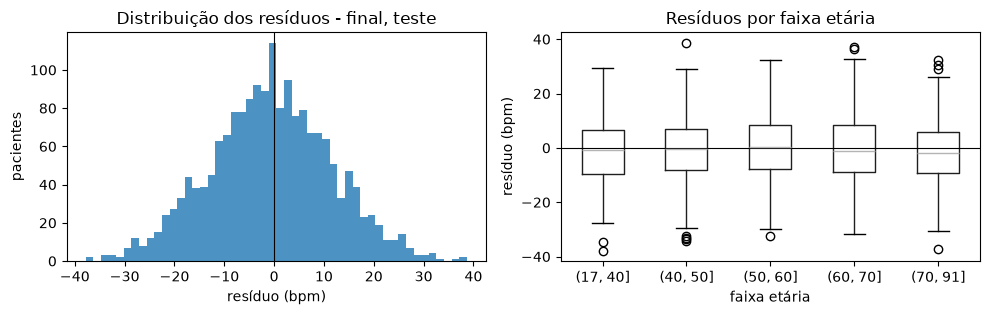

média             -0.648
desvio            12.147
mediana           -0.565
% |e| > 20 bpm    10.500
% |e| > 30 bpm     1.167
corr(ŷ, e)        -0.014
corr(y, e)         0.555
dtype: float64

In [13]:
prev = PREV_REG[("Final", "teste")]
res = y - prev
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
axes[0].hist(res, bins=50, color="#1f77b4", alpha=0.8)
axes[0].axvline(0, color="k", lw=0.8)
axes[0].set(xlabel="resíduo (bpm)", ylabel="pacientes", title="Distribuição dos resíduos - final, teste")
faixas = pd.cut(df_te["age"], [17, 40, 50, 60, 70, 91])
pd.DataFrame({"faixa etária": faixas, "resíduo": res}).boxplot(column="resíduo", by="faixa etária", ax=axes[1], grid=False)
axes[1].axhline(0, color="k", lw=0.8); axes[1].set(title="Resíduos por faixa etária", ylabel="resíduo (bpm)")
fig.suptitle(""); fig.tight_layout()
salvar_fig("residuos_distribuicao")
plt.show()
estat_res = pd.Series({"média": res.mean(), "desvio": res.std(), "mediana": np.median(res),
                       "% |e| > 20 bpm": 100 * np.mean(np.abs(res) > 20),
                       "% |e| > 30 bpm": 100 * np.mean(np.abs(res) > 30),
                       "corr(ŷ, e)": np.corrcoef(prev, res)[0, 1],
                       "corr(y, e)": np.corrcoef(y, res)[0, 1]})
estat_res.round(3)

## 5. Generalização

### 5.1 Gap de generalização

Gap = desempenho no treino − desempenho no teste. Para o F1, gap > 0 indica queda fora do treino; para o RMSE
(erro), o sinal se inverte e gap < 0 indica erro maior no teste. O gap relativo é sempre a perda de desempenho
fora do treino em % do valor de treino (> 0 = pior fora do treino).

In [14]:
linhas = []
for p, met, tab in (("regressao", "RMSE", met_reg), ("classificacao", "F1", met_clf)):
    for nome in ("Baseline", "Final"):
        t = tab[tab["modelo"] == f"MLP {nome}"].set_index("conjunto")[met]
        linhas.append({"problema": p, "modelo": f"MLP {nome}", "métrica": met, "treino": t["treino"],
                       "validação": t["validação"], "teste": t["teste"], "gap (treino - teste)": gap(t["treino"], t["teste"]),
                       "gap relativo (%)": 100 * gap_relativo(t["treino"], t["teste"], p)})
gaps = pd.DataFrame(linhas)
salvar_tabela(gaps, "gap_generalizacao")
gaps.round(4)

,problema,modelo,métrica,treino,validação,teste,gap (treino - teste),gap relativo (%)
0,regressao,MLP Baseline,RMSE,11.5654,11.7231,12.3284,-0.7630,6.5975
1,regressao,MLP Final,RMSE,11.7692,11.6727,12.1641,-0.3948,3.3549
2,classificacao,MLP Baseline,F1,0.8506,0.8278,0.8086,0.0420,4.9397
3,classificacao,MLP Final,F1,0.8411,0.8316,0.8216,0.0195,2.3212


### 5.2 Curvas de aprendizado do modelo final

Perda de treino e de validação por época (o histórico foi salvo no checkpoint). A linha tracejada marca a época
do melhor estado restaurado pelo early stopping; o treino continuou por mais `paciência` épocas sem melhora.

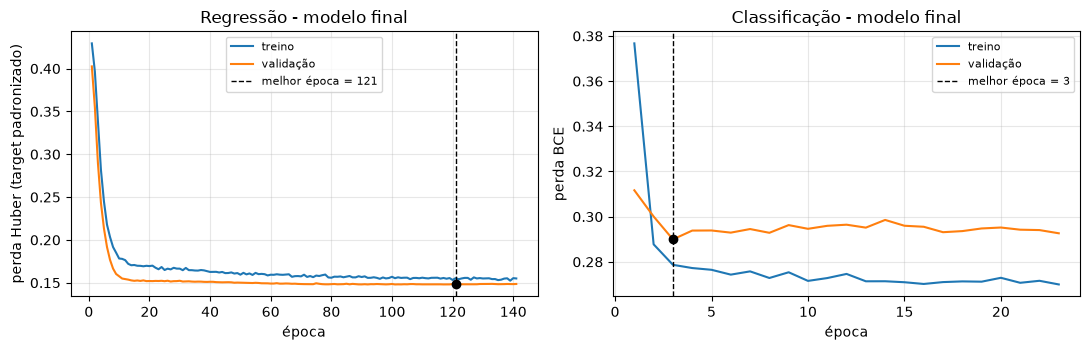

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, p in zip(axes, ("regressao", "classificacao")):
    ck = MODELOS[p]["Final"][1]
    h = ck["historico"]
    ep = np.arange(1, len(h["treino"]) + 1)
    ax.plot(ep, h["treino"], label="treino"); ax.plot(ep, h["val"], label="validação")
    me = ck["melhor_epoca"]
    ax.axvline(me, color="k", ls="--", lw=1, label=f"melhor época = {me}")
    ax.scatter([me], [h["val"][me - 1]], color="k", zorder=3)
    perda = {"regressao": ck["hiperparametros"]["perda"] + " (target padronizado)", "classificacao": "BCE"}[p]
    ax.set(xlabel="época", ylabel=f"perda {perda}",
           title=f"{'Regressão' if p == 'regressao' else 'Classificação'} - modelo final")
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout()
salvar_fig("curvas_aprendizado_final")
plt.show()

### 5.3 Validação cruzada K-fold (K = 5) da configuração final

Os 7.200 pacientes de treino (treino + validação) são divididos em 5 folds estratificados. Em cada rodada, 4 folds
treinam e o quinto avalia; dentro dos 4 folds de treino, 20% são separados para o early stopping, de modo que o
fold de avaliação não influencia o treino. O padronizador é reajustado em cada rodada só com os dados de treino da
rodada. O teste não participa.

In [16]:
def kfold(problema, cfg, k=5, seed=0):
    df = ler_dataset(problema)
    _, _, idx_te, idx_tr_total = indices_split(df)
    estrato = df["has_heart_disease"]
    skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)
    linhas = []
    for f, (a, b) in enumerate(skf.split(idx_tr_total, estrato.loc[idx_tr_total]), 1):
        idx_fit_total, idx_aval = idx_tr_total[a], idx_tr_total[b]
        idx_fit, idx_es = train_test_split(idx_fit_total, test_size=0.2, random_state=42,
                                           stratify=estrato.loc[idx_fit_total])
        dados = preparar(problema, idx_fit, idx_es, idx_aval)
        r, h, m = executar(cfg, dados, seed, retornar_modelo=True)
        lim = MODELOS[problema]["Final"][1].get("limiar", 0.5)
        m_aval = avaliar(m, dados, dados.X_te, dados.y_te_orig, limiar=lim)
        linhas.append({"fold": f, "melhor_epoca": r["melhor_epoca"], **{f"treino_{kk}": r[f"treino_{kk}"] for kk in ("RMSE", "F1") if f"treino_{kk}" in r},
                       **m_aval})
    return pd.DataFrame(linhas)

CV = {}
for p, met in (("regressao", "RMSE"), ("classificacao", "F1")):
    cfg = MODELOS[p]["Final"][1]["hiperparametros"]
    seed = MODELOS[p]["Final"][1]["seed"]
    CV[p] = kfold(p, cfg, seed=seed)
    salvar_tabela(CV[p], f"kfold_{p}")
    print(f"{p}: {met} K-fold = {CV[p][met].mean():.4f} ± {CV[p][met].std():.4f}")
display(CV["regressao"].round(3)); display(CV["classificacao"].round(4))

regressao: RMSE K-fold = 11.9180 ± 0.1406


classificacao: F1 K-fold = 0.8355 ± 0.0163


,fold,melhor_epoca,treino_RMSE,MAE,MSE,RMSE,MAPE (%),R2,MedAE
0,1,63,11.819,9.467,139.575,11.814,5.876,0.680,8.063
1,2,78,11.774,9.511,142.560,11.940,5.895,0.672,8.034
2,3,123,11.693,9.473,142.253,11.927,5.831,0.699,7.934
3,4,22,12.006,9.625,147.254,12.135,6.009,0.678,7.943
4,5,88,11.758,9.529,138.627,11.774,5.959,0.696,8.378


,fold,melhor_epoca,treino_F1,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,1,16,0.8420,0.8868,0.8031,0.8307,0.8166,0.9487,0.8973
1,2,9,0.8319,0.9007,0.8500,0.8169,0.8331,0.9526,0.9124
2,3,8,0.8367,0.9167,0.8709,0.8509,0.8608,0.9622,0.9239
3,4,17,0.8413,0.8958,0.8265,0.8303,0.8284,0.9502,0.9168
4,5,4,0.8346,0.9021,0.8375,0.8394,0.8385,0.9559,0.9176


### 5.4 Diagnóstico: modelo final e configurações extremas do estudo

Critério (adaptado do usado na Atividade 2), aplicado com a validação (média de 5 sementes) no lugar do teste para
as configurações do estudo, já que o teste não pode ser usado para elas. Avaliado nesta ordem:
- **underfitting:** a métrica no **próprio treino** é > 5% pior que a melhor métrica de validação do estudo
  (alto viés: o modelo não ajusta nem os dados que viu);
- **overfitting:** gap relativo treino → validação > 10% (alta variância);
- **bem ajustado:** caso contrário.

O viés é verificado primeiro para que um modelo que colapsou (erro de treino alto e erro de validação ainda maior,
como η = 1) não seja classificado como overfitting só por ter gap grande.

In [17]:
log = carregar_log()
extremos = {"neuronios": ["2", "128"], "camadas": ["1", "5"], "lr": ["0.0001", "1.0"],
            "batch": ["8", "total"], "weight_decay": ["0.0", "0.01"], "dropout": ["0.0", "0.5"],
            "ativacao": ["Sigmoid", "ReLU"], "epocas_es": ["200 ép., pac. 20", "500 ép., sem ES"]}
linhas = []
for p, met in (("regressao", "RMSE"), ("classificacao", "F1")):
    est = estudos(p)
    melhor_val = (log[log["problema"] == p].groupby("chave")[f"val_{met}"].mean())
    melhor_val = melhor_val.max() if met == "F1" else melhor_val.min()
    for hp, valores in extremos.items():
        tab = resumir(p, est[hp], log).set_index("valor")
        for v in valores:
            r = tab.loc[v]
            tr, va = r[f"treino_{met}_media"], r[f"val_{met}_media"]
            linhas.append({"problema": p, "configuração": f"{hp} = {v}", "n_parametros": r["n_parametros"],
                           f"treino": tr, "validação": va, "desvio val": r[f"val_{met}_desvio"],
                           "gap relativo (%)": 100 * gap_relativo(tr, va, p),
                           "diagnóstico": diagnostico(tr, va, melhor_val, p)})
    ck = MODELOS[p]["Final"][1]
    t = (met_reg if p == "regressao" else met_clf).query("modelo == 'MLP Final'").set_index("conjunto")[met]
    linhas.append({"problema": p, "configuração": "FINAL (teste)", "n_parametros": sum(v.numel() for v in ck["state_dict"].values()),
                   "treino": t["treino"], "validação": t["teste"], "desvio val": np.nan,
                   "gap relativo (%)": 100 * gap_relativo(t["treino"], t["teste"], p),
                   "diagnóstico": diagnostico(t["treino"], t["teste"], melhor_val, p)})
diag = pd.DataFrame(linhas)
salvar_tabela(diag, "diagnostico_extremos")
diag.round(4)

,problema,configuração,n_parametros,treino,validação,desvio val,gap relativo (%),diagnóstico
0,regressao,neuronios = 2,71,13.7358,13.5381,4.1780,-1.4394,underfitting
1,regressao,neuronios = 128,20609,11.5135,11.8981,0.0627,3.3400,bem ajustado
2,regressao,camadas = 1,1025,11.6755,11.7582,0.0495,0.7083,bem ajustado
3,regressao,camadas = 5,5249,11.6201,11.8897,0.1054,2.3197,bem ajustado
4,regressao,lr = 0.0001,2081,11.5952,11.8430,0.0891,2.1375,bem ajustado
5,regressao,lr = 1.0,2081,21.3444,33.8614,26.3236,58.6435,underfitting
6,regressao,batch = 8,2081,11.6336,11.8585,0.0735,1.9332,bem ajustado
7,regressao,batch = total,2081,11.5980,11.9231,0.0941,2.8030,bem ajustado
8,regressao,weight_decay = 0.0,2081,11.6388,11.8444,0.0776,1.7671,bem ajustado
9,regressao,weight_decay = 0.01,2081,11.5601,11.7601,0.0488,1.7299,bem ajustado


### 5.5 Trade-off viés × variância

Treino e validação em função da capacidade (neurônios por camada, com 2 camadas) e da regularização (weight decay),
a partir do estudo de hiperparâmetros (média ± desvio de 5 sementes).

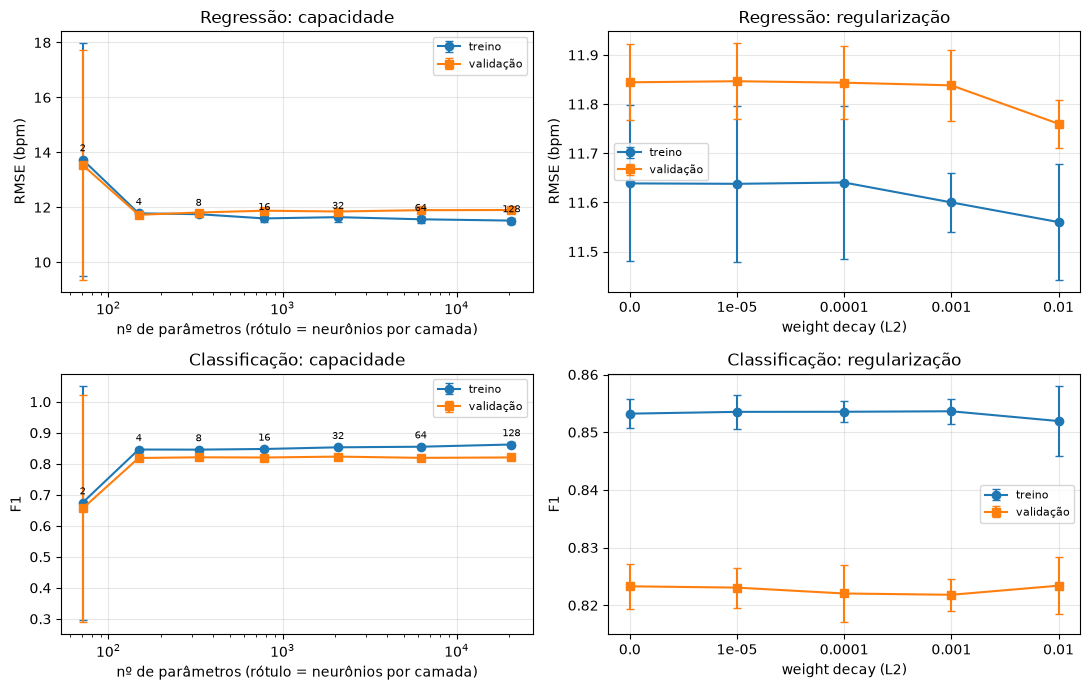

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for i, (p, met) in enumerate((("regressao", "RMSE"), ("classificacao", "F1"))):
    for j, hp in enumerate(("neuronios", "weight_decay")):
        tab = resumir(p, estudos(p)[hp], log)
        ax = axes[i, j]
        x = tab["n_parametros"] if hp == "neuronios" else np.arange(len(tab))
        ax.errorbar(x, tab[f"treino_{met}_media"], tab[f"treino_{met}_desvio"], fmt="o-", capsize=3, label="treino")
        ax.errorbar(x, tab[f"val_{met}_media"], tab[f"val_{met}_desvio"], fmt="s-", capsize=3, label="validação")
        if hp == "neuronios":
            ax.set_xscale("log")
            for xx, v, yy in zip(x, tab["valor"], tab[f"treino_{met}_media"]):
                ax.annotate(v, (xx, yy), textcoords="offset points", xytext=(0, 6), fontsize=7, ha="center")
            ax.set_xlabel("nº de parâmetros (rótulo = neurônios por camada)")
        else:
            ax.set_xticks(x, tab["valor"]); ax.set_xlabel("weight decay (L2)")
        ax.set_ylabel(met + (" (bpm)" if met == "RMSE" else ""))
        ax.set_title(f"{'Regressão' if p == 'regressao' else 'Classificação'}: {'capacidade' if hp == 'neuronios' else 'regularização'}")
        ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout()
salvar_fig("vies_variancia")
plt.show()